# Audit visuel des classes problématiques

Notebook **autonome**, séparé de `hierarchy_pytorch.ipynb` -- ne modifie rien à l'entraînement.
Recharge les 5 modèles déjà entraînés (sans ré-entraînement) et fournit un outil générique
d'audit visuel : afficher une grille d'images pour n'importe quelle paire (classe réelle,
classe prédite), en plus d'appels pré-configurés sur les confusions déjà identifiées comme
problématiques dans le projet :

- `Monoblast` -> `Monocyte` (erreur de routage au Niveau 1, jamais auditée)
- `Metamyelocyte` / `Myelocyte` -> `Neutrophil (band)` (confirmé par la section de comparaison
  collègues -- 19% des Metamyelocyte fuient ainsi)
- `Promyelocyte` -> rejeté (48% correct / 45% rejet, jamais amélioré malgré plusieurs
  restructurations)
- `Neutrophil (band)` <-> `Neutrophil (segmented)` (confusion mutuelle résiduelle)

**Important** : pointez `RELOAD_MODELS_DIR` vers l'endroit où vous avez republié vos modèles
(dataset Kaggle, ou `/kaggle/working/models` si même session).

## 1. Configuration (identique à `hierarchy_pytorch.ipynb`)

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2

DATASET_DIR_RAW = Path("/kaggle/input/datasets/jfonlupt/dataset-fusion/dataset_fusionne_filtre")

def resolve_dataset_dir(root):
    current = root
    while current.exists():
        subdirs = [d for d in current.iterdir() if d.is_dir()]
        if len(subdirs) == 1:
            current = subdirs[0]
        else:
            break
    return current

DATASET_DIR = resolve_dataset_dir(DATASET_DIR_RAW)
print("DATASET_DIR (résolu) :", DATASET_DIR, "| existe ?", DATASET_DIR.exists())

# NOUVEAU : les grilles d'audit sont sauvegardées ici, comme hierarchy_pytorch.ipynb --
# simplifie et normalise le transfert des résultats vers le chat (zip du dossier output).
OUTPUT_DIR = Path("/kaggle/working")
AUDIT_DIR = OUTPUT_DIR / "audits"
AUDIT_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_SEED = 42
BATCH_SIZE = 32

# <-- À adapter si vous rechargez depuis un dataset Kaggle republié
RELOAD_MODELS_DIR = Path("/kaggle/input/models/jfonlupt/2026-09-09-model/pytorch/default/1/2026-09-09 modele")   # dataset Kaggle publié -- fonctionne à chaque session

FOLDER_TO_TARGET = {
    "Neutrophil (segmented)": "Neutrophil (segmented)",
    "Lymphocyte (typical)": "Lymphocyte",
    "Lymphocyte (atypical)": "Lymphocyte",
    "Eosinophil": "Eosinophil",
    "Myeloblast": "Myeloblast",
    "Monocyte": "Monocyte",
    "Platelet": "Platelet",
    "Neutrophil (band)": "Neutrophil (band)",
    "Erythroblast": "Erythroblast",
    "Basophil": "Basophil",
    "Myelocyte": "Myelocyte",
    "Metamyelocyte": "Metamyelocyte",
    "Promyelocyte": "Promyelocyte",
    "Promyelocyte (bilobed)": "Promyelocyte",
    "Monoblast": "Monoblast",
    "Immature Granulocyte": "Granulocytes immatures de PBC",
}

with open(RELOAD_MODELS_DIR / "artifacts.json", encoding="utf-8") as f:
    artifacts = json.load(f)

IMG_SIZE = artifacts["IMG_SIZE"]
TARGET_CLASSES = artifacts["TARGET_CLASSES"]
CLASS_TO_IDX = {c: i for i, c in enumerate(TARGET_CLASSES)}
LEVEL1_CLASSES = artifacts["LEVEL1_CLASSES"]
LEVEL1_ISOLATED = artifacts["LEVEL1_ISOLATED"]
GRANULOCYTIC_GROUP_LABEL = artifacts["GRANULOCYTIC_GROUP_LABEL"]
LEVEL3_CLASSES = artifacts["LEVEL3_CLASSES"]
RESTE_LABEL_L3 = artifacts["RESTE_LABEL_L3"]
LEVEL3_CLASS_TO_IDX = {c: i for i, c in enumerate(LEVEL3_CLASSES)}
IG_LABEL = artifacts["IG_LABEL"]
LEVEL4_CLASSES = artifacts["LEVEL4_CLASSES"]
REJECT_LABEL = artifacts["REJECT_LABEL"]
T_ACCEPT_L4 = artifacts["T_ACCEPT_L4"]
T_ACCEPT_L5 = artifacts["T_ACCEPT_L5"]

def to_level1_label(class_name):
    return class_name if class_name in LEVEL1_ISOLATED else GRANULOCYTIC_GROUP_LABEL

print(f"Artefacts chargés -- {len(TARGET_CLASSES)} classes, seuils T_ACCEPT_L4={T_ACCEPT_L4:.4f}, "
      f"T_ACCEPT_L5={T_ACCEPT_L5:.4f}")
np.random.seed(RANDOM_SEED)


DATASET_DIR (résolu) : /kaggle/input/datasets/jfonlupt/dataset-fusion/dataset_fusionne_filtre | existe ? True
Artefacts chargés -- 14 classes, seuils T_ACCEPT_L4=0.8375, T_ACCEPT_L5=0.6688


## 2. Chargement des données et split (identique -- même graine aléatoire, même test set)

In [2]:
def load_fused_dataset():
    if not DATASET_DIR.exists():
        raise FileNotFoundError(f"DATASET_DIR introuvable : {DATASET_DIR}")
    rows = []
    for class_dir in sorted(DATASET_DIR.iterdir()):
        if not class_dir.is_dir():
            continue
        target_label = FOLDER_TO_TARGET.get(class_dir.name)
        if target_label is None:
            continue
        for f in class_dir.iterdir():
            if f.suffix.lower() in (".png", ".jpg", ".jpeg", ".tif", ".tiff"):
                rows.append({"path": f, "class_name": class_dir.name, "target_label": target_label})
    if not rows:
        raise ValueError(f"Aucune image trouvée dans {DATASET_DIR}")
    df = pd.DataFrame(rows)
    df["label_idx"] = df["target_label"].map(CLASS_TO_IDX)
    df["level1_label"] = df["target_label"].apply(to_level1_label)
    return df


data = load_fused_dataset()
print(f"Total images exploitables : {len(data)}")

from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(data, test_size=0.30, stratify=data["target_label"], random_state=RANDOM_SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df["target_label"], random_state=RANDOM_SEED)
print(f"Train : {len(train_df)} | Val : {len(val_df)} | Test : {len(test_df)}  (même split que l'entraînement original)")


Total images exploitables : 33577
Train : 23503 | Val : 5037 | Test : 5037  (même split que l'entraînement original)


## 3. Fonctions utilitaires PyTorch (identiques -- nécessaires pour recharger les modèles)

In [3]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision.models import efficientnet_b0

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device utilisé : {DEVICE}")

IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
IMAGENET_STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)


class CellDataset(Dataset):
    def __init__(self, paths, labels=None):
        self.paths = list(paths)
        self.labels = labels if labels is not None else [0] * len(self.paths)

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        img = cv2.imread(str(self.paths[idx]), cv2.IMREAD_COLOR)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img = cv2.resize(img, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)
        img = img.astype(np.float32) / 255.0
        img = torch.from_numpy(img).permute(2, 0, 1)
        return img, self.labels[idx]


def make_loader(paths, shuffle=False):
    ds = CellDataset(paths)
    return DataLoader(ds, batch_size=BATCH_SIZE, shuffle=shuffle, num_workers=2, pin_memory=True)


def normalize_batch(imgs):
    return (imgs - IMAGENET_MEAN.to(imgs.device)) / IMAGENET_STD.to(imgs.device)


class FullModel(nn.Module):
    def __init__(self, n_outputs):
        super().__init__()
        base = efficientnet_b0(weights=None)   # poids ImageNet non nécessaires : on recharge nos propres poids
        self.features = base.features
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.dropout1 = nn.Dropout(0.4)
        self.fc1 = nn.Linear(1280, 128)
        self.relu = nn.ReLU()
        self.dropout2 = nn.Dropout(0.3)
        self.fc2 = nn.Linear(128, n_outputs)

    def forward(self, x):
        x = normalize_batch(x)
        x = self.features(x)
        x = self.pool(x).flatten(1)
        x = self.dropout1(x)
        x = self.relu(self.fc1(x))
        x = self.dropout2(x)
        return self.fc2(x)


@torch.no_grad()
def predict_proba_paths(model, paths, task="multiclass"):
    if len(paths) == 0:
        return np.zeros((0, 1))
    model.eval()
    loader = make_loader(paths, shuffle=False)
    all_proba = []
    for imgs, _ in loader:
        imgs = imgs.to(DEVICE, non_blocking=True)
        logits = model(imgs)
        proba = torch.softmax(logits, dim=1) if task == "multiclass" else torch.sigmoid(logits)
        all_proba.append(proba.cpu().numpy())
    return np.concatenate(all_proba, axis=0)


Device utilisé : cpu


## 4. Rechargement des 5 modèles (sans ré-entraînement)

In [4]:
level1_model = FullModel(len(LEVEL1_CLASSES)).to(DEVICE)
level1_model.load_state_dict(torch.load(RELOAD_MODELS_DIR / "level1.pt", map_location=DEVICE, weights_only=True))
level1_model.eval()

level2_model = FullModel(1).to(DEVICE)
level2_model.load_state_dict(torch.load(RELOAD_MODELS_DIR / "level2.pt", map_location=DEVICE, weights_only=True))
level2_model.eval()

level3_model = FullModel(len(LEVEL3_CLASSES)).to(DEVICE)
level3_model.load_state_dict(torch.load(RELOAD_MODELS_DIR / "level3.pt", map_location=DEVICE, weights_only=True))
level3_model.eval()

level4_model = FullModel(len(LEVEL4_CLASSES)).to(DEVICE)
level4_model.load_state_dict(torch.load(RELOAD_MODELS_DIR / "level4.pt", map_location=DEVICE, weights_only=True))
level4_model.eval()

level5_model = FullModel(1).to(DEVICE)
level5_model.load_state_dict(torch.load(RELOAD_MODELS_DIR / "level5.pt", map_location=DEVICE, weights_only=True))
level5_model.eval()

print("Les 5 modèles ont été rechargés sans ré-entraînement.")


Les 5 modèles ont été rechargés sans ré-entraînement.


## 5. Cascade complète sur le jeu de test

Reproduit exactement la logique de `predict_cascade_batch` de `hierarchy_pytorch.ipynb` --
nécessaire pour obtenir les prédictions à auditer.

In [5]:
def predict_cascade_batch(paths):
    n = len(paths)
    final_labels = np.empty(n, dtype=object)
    final_confidence = np.zeros(n, dtype=float)

    l1_proba = predict_proba_paths(level1_model, paths, task="multiclass")
    l1_pred_idx = l1_proba.argmax(axis=1)
    l1_confidence = l1_proba.max(axis=1)
    l1_pred_label = np.array([LEVEL1_CLASSES[i] for i in l1_pred_idx])

    is_granulo = l1_pred_label == GRANULOCYTIC_GROUP_LABEL
    final_labels[~is_granulo] = l1_pred_label[~is_granulo]
    final_confidence[~is_granulo] = l1_confidence[~is_granulo]

    if is_granulo.sum() > 0:
        granulo_idx = np.where(is_granulo)[0]
        granulo_paths = [paths[i] for i in granulo_idx]

        l2_proba = predict_proba_paths(level2_model, granulo_paths, task="binary").ravel()
        is_eosinophil = l2_proba >= 0.5
        final_labels[granulo_idx[is_eosinophil]] = "Eosinophil"
        final_confidence[granulo_idx[is_eosinophil]] = l2_proba[is_eosinophil]

        remaining_idx_1 = granulo_idx[~is_eosinophil]
        if len(remaining_idx_1) > 0:
            l3_paths = [paths[i] for i in remaining_idx_1]
            l3_proba = predict_proba_paths(level3_model, l3_paths, task="multiclass")
            l3_pred_idx = l3_proba.argmax(axis=1)
            l3_confidence = l3_proba.max(axis=1)

            idx_reste = LEVEL3_CLASS_TO_IDX[RESTE_LABEL_L3]
            is_terminal = l3_pred_idx != idx_reste
            is_reste = l3_pred_idx == idx_reste

            terminal_labels = np.array([LEVEL3_CLASSES[i] for i in l3_pred_idx], dtype=object)
            final_labels[remaining_idx_1[is_terminal]] = terminal_labels[is_terminal]
            final_confidence[remaining_idx_1[is_terminal]] = l3_confidence[is_terminal]

            remaining_idx_2 = remaining_idx_1[is_reste]
            if len(remaining_idx_2) > 0:
                l4_paths = [paths[i] for i in remaining_idx_2]
                l4_proba = predict_proba_paths(level4_model, l4_paths, task="multiclass")
                l4_pred_idx = l4_proba.argmax(axis=1)
                l4_confidence = l4_proba.max(axis=1)
                l4_pred_label = np.array([LEVEL4_CLASSES[i] for i in l4_pred_idx], dtype=object)
                accepted_l4 = l4_confidence >= T_ACCEPT_L4
                l4_pred_label_final = l4_pred_label.copy()
                l4_pred_label_final[~accepted_l4] = REJECT_LABEL
                final_labels[remaining_idx_2] = l4_pred_label_final
                final_confidence[remaining_idx_2] = l4_confidence

                is_ig_pred = l4_pred_label == IG_LABEL
                ig_idx = remaining_idx_2[is_ig_pred]
                if len(ig_idx) > 0:
                    ig_paths = [paths[i] for i in ig_idx]
                    l5_proba = predict_proba_paths(level5_model, ig_paths, task="binary").ravel()
                    l5_confirmed = l5_proba >= 0.5
                    l5_confidence = np.where(l5_confirmed, l5_proba, 1 - l5_proba)
                    accepted_l5 = l5_confirmed & (l5_confidence >= T_ACCEPT_L5)
                    final_labels[ig_idx[~accepted_l5]] = REJECT_LABEL
                    final_confidence[ig_idx[~accepted_l5]] = l5_confidence[~accepted_l5]

    return final_labels, final_confidence


test_pred_final, test_confidence_final = predict_cascade_batch(list(test_df["path"].astype(str).values))
test_true_final = test_df["target_label"].values

decided_mask = test_pred_final != REJECT_LABEL
print(f"Décisions fermes : {decided_mask.sum()}/{len(test_df)} "
      f"({decided_mask.sum()/len(test_df)*100:.1f}%) -- accuracy "
      f"{(test_pred_final[decided_mask]==test_true_final[decided_mask]).mean()*100:.2f}%")


/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Décisions fermes : 4726/5037 (93.8%) -- accuracy 93.80%


## 6. Fonction d'audit générique

`show_class_audit(true_class, pred_class=None, n=25, seed=42)` :
- `pred_class` **précis** (ex. `"Monocyte"`) : n'affiche que les cas `true_class -> pred_class`
- `pred_class="A confirmer manuellement"` : affiche les cas rejetés pour cette classe réelle
- `pred_class=None` : affiche **toutes** les erreurs pour `true_class`, quelle que soit la
  classe prédite (utile en exploration libre)

In [6]:
import re


def show_class_audit(true_class, pred_class=None, n=25, seed=42, only_errors=True):
    """Affiche une grille d'images correspondant à (true_class, pred_class).

    - pred_class=None (défaut) : toutes les prédictions erronées pour true_class
      (le mot juste diagnostic, quelle que soit la classe reçue -- y compris le rejet).
    - pred_class=<nom de classe> ou REJECT_LABEL : filtre précisément sur ce couple.
    - only_errors=False : inclut aussi les cas CORRECTS (utile pour comparer visuellement
      les cas bien classés vs mal classés d'une même classe réelle).
    """
    is_true_class = test_true_final == true_class
    if pred_class is not None:
        mask = is_true_class & (test_pred_final == pred_class)
        title = f"{true_class} -> {pred_class}"
    elif only_errors:
        mask = is_true_class & (test_pred_final != test_true_final)
        title = f"{true_class} -- toutes erreurs (y compris rejet)"
    else:
        mask = is_true_class
        title = f"{true_class} -- tous les cas (corrects + erreurs)"

    n_found = int(mask.sum())
    print(f"{n_found} images trouvées pour '{title}' (sur {int(is_true_class.sum())} images de "
          f"'{true_class}' au total dans le test)")
    if n_found == 0:
        return

    subset_df = test_df[mask].reset_index(drop=True)
    subset_pred = test_pred_final[mask]
    subset_conf = test_confidence_final[mask]

    sample_size = min(n, n_found)
    sample_idx = np.random.RandomState(seed).choice(n_found, size=sample_size, replace=False)

    n_cols = 5
    n_rows = int(np.ceil(sample_size / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 3, n_rows * 3))
    axes = np.array(axes).reshape(-1)
    for ax, idx in zip(axes, sample_idx):
        img = cv2.cvtColor(cv2.imread(str(subset_df.iloc[idx]["path"])), cv2.COLOR_BGR2RGB)
        ax.imshow(img)
        pred_label = subset_pred[idx] if subset_pred[idx] != REJECT_LABEL else "Rejeté"
        ax.set_title(f"Vrai: {true_class}\nPrédit: {pred_label}\nconf={subset_conf[idx]:.2f}", fontsize=8)
        ax.axis("off")
    for ax in axes[sample_size:]:
        ax.axis("off")
    plt.suptitle(title, fontsize=13)
    plt.tight_layout()

    # NOUVEAU : sauvegarde systématique avant affichage -- nom de fichier explicite et
    # sûr (slashes/parenthèses de "Neutrophil (band)" etc. remplacés).
    safe_true = re.sub(r"[^A-Za-z0-9]+", "_", true_class).strip("_")
    safe_pred = re.sub(r"[^A-Za-z0-9]+", "_", pred_class).strip("_") if pred_class is not None else "toutes_erreurs"
    filename = f"audit_{safe_true}_vers_{safe_pred}.png"
    plt.savefig(AUDIT_DIR / filename, dpi=120, bbox_inches="tight")
    print(f"Grille sauvegardée : {AUDIT_DIR / filename}")

    plt.show()


## 7. Audits pré-configurés sur les cas identifiés comme problématiques

Chaque appel peut être commenté/décommenté ou dupliqué avec d'autres classes selon vos besoins.

1 images trouvées pour 'Monoblast -> Monocyte' (sur 3 images de 'Monoblast' au total dans le test)
Grille sauvegardée : /kaggle/working/audits/audit_Monoblast_vers_Monocyte.png


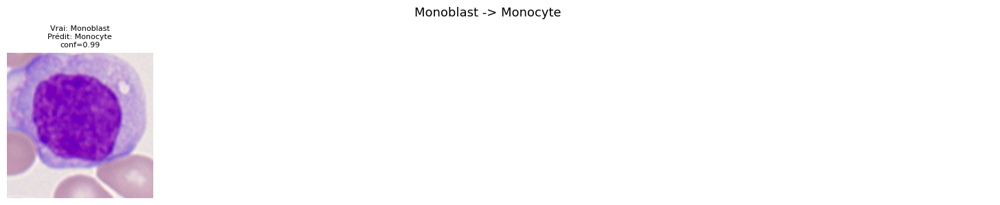

In [7]:
# --- Monoblast -> Monocyte : erreur de routage au Niveau 1, jamais auditée ---
show_class_audit("Monoblast", "Monocyte")


2 images trouvées pour 'Monoblast -> A confirmer manuellement' (sur 3 images de 'Monoblast' au total dans le test)
Grille sauvegardée : /kaggle/working/audits/audit_Monoblast_vers_A_confirmer_manuellement.png


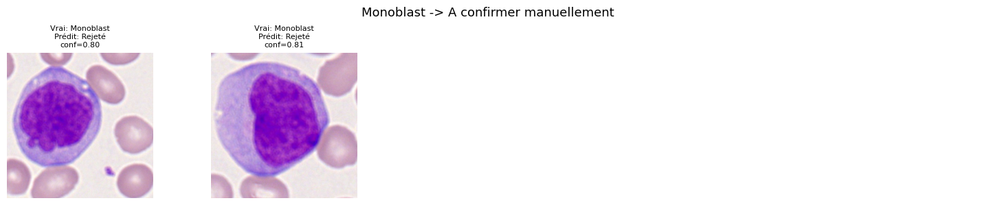

In [8]:
# --- Monoblast -> rejeté : le reste des erreurs pour cette classe ---
show_class_audit("Monoblast", REJECT_LABEL)


8 images trouvées pour 'Metamyelocyte -> Neutrophil (band)' (sur 150 images de 'Metamyelocyte' au total dans le test)
Grille sauvegardée : /kaggle/working/audits/audit_Metamyelocyte_vers_Neutrophil_band.png


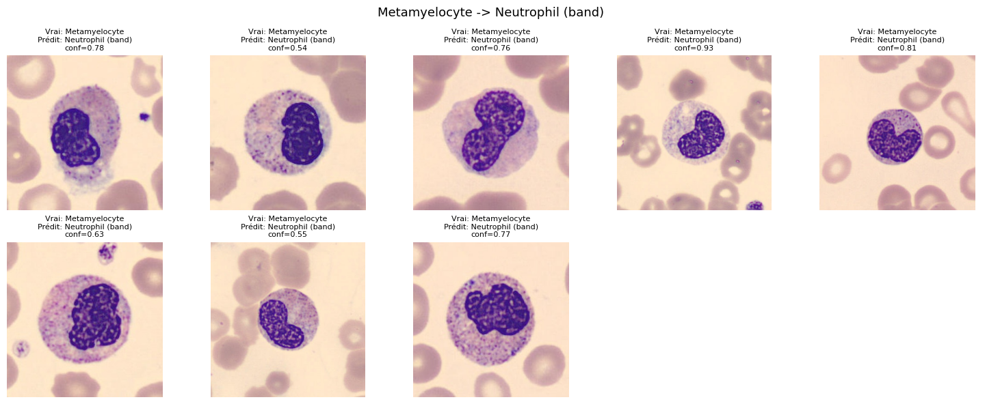

In [9]:
# --- Metamyelocyte -> Neutrophil (band) : confirmé par la comparaison collègues (19% de fuite) ---
show_class_audit("Metamyelocyte", "Neutrophil (band)")


4 images trouvées pour 'Myelocyte -> Neutrophil (band)' (sur 171 images de 'Myelocyte' au total dans le test)
Grille sauvegardée : /kaggle/working/audits/audit_Myelocyte_vers_Neutrophil_band.png


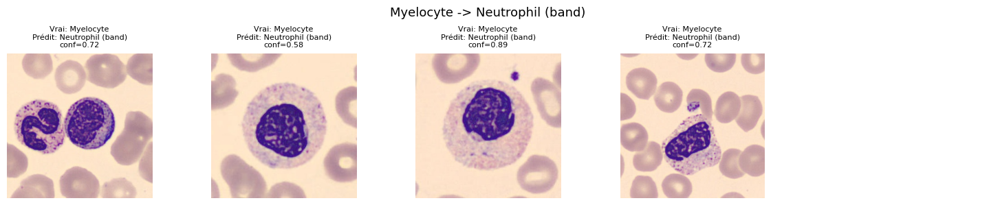

In [10]:
# --- Myelocyte -> Neutrophil (band) ---
show_class_audit("Myelocyte", "Neutrophil (band)")


44 images trouvées pour 'Promyelocyte -> A confirmer manuellement' (sur 97 images de 'Promyelocyte' au total dans le test)
Grille sauvegardée : /kaggle/working/audits/audit_Promyelocyte_vers_A_confirmer_manuellement.png


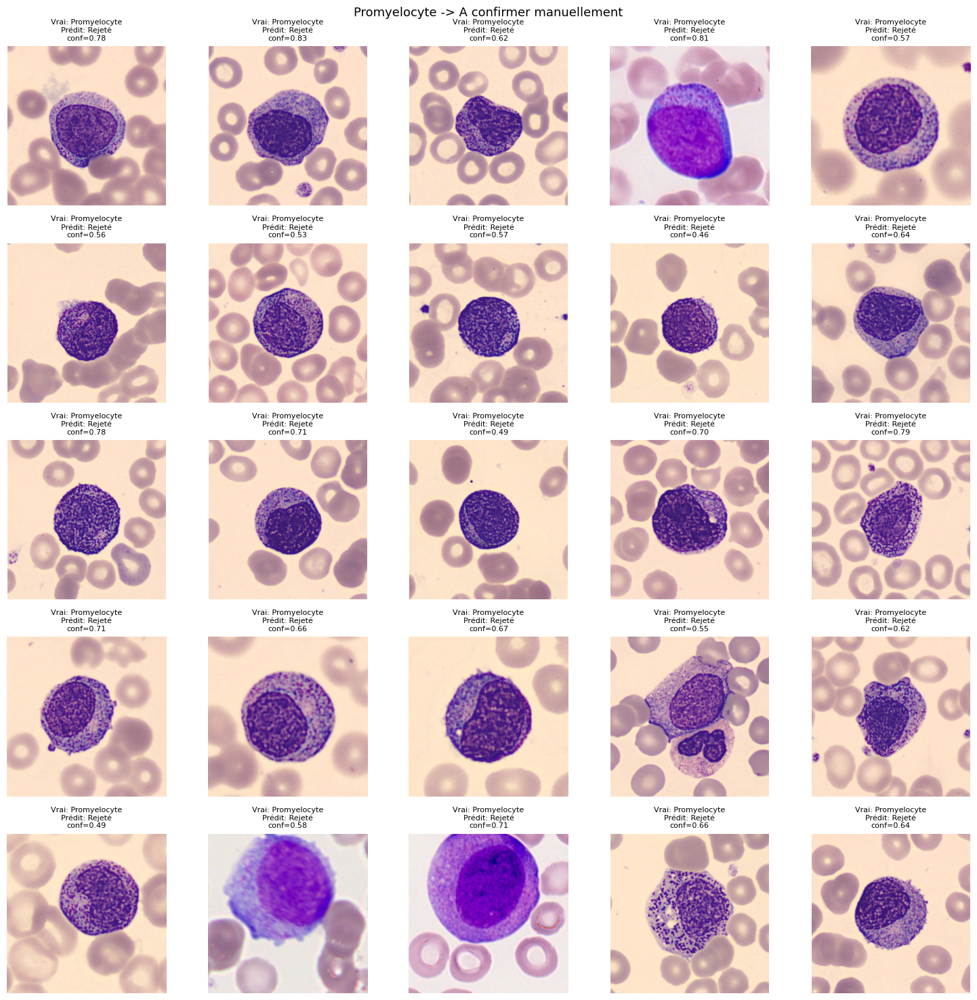

In [11]:
# --- Promyelocyte -> rejeté (45% des cas) ---
show_class_audit("Promyelocyte", REJECT_LABEL)


38 images trouvées pour 'Neutrophil (band) -> Neutrophil (segmented)' (sur 257 images de 'Neutrophil (band)' au total dans le test)
Grille sauvegardée : /kaggle/working/audits/audit_Neutrophil_band_vers_Neutrophil_segmented.png


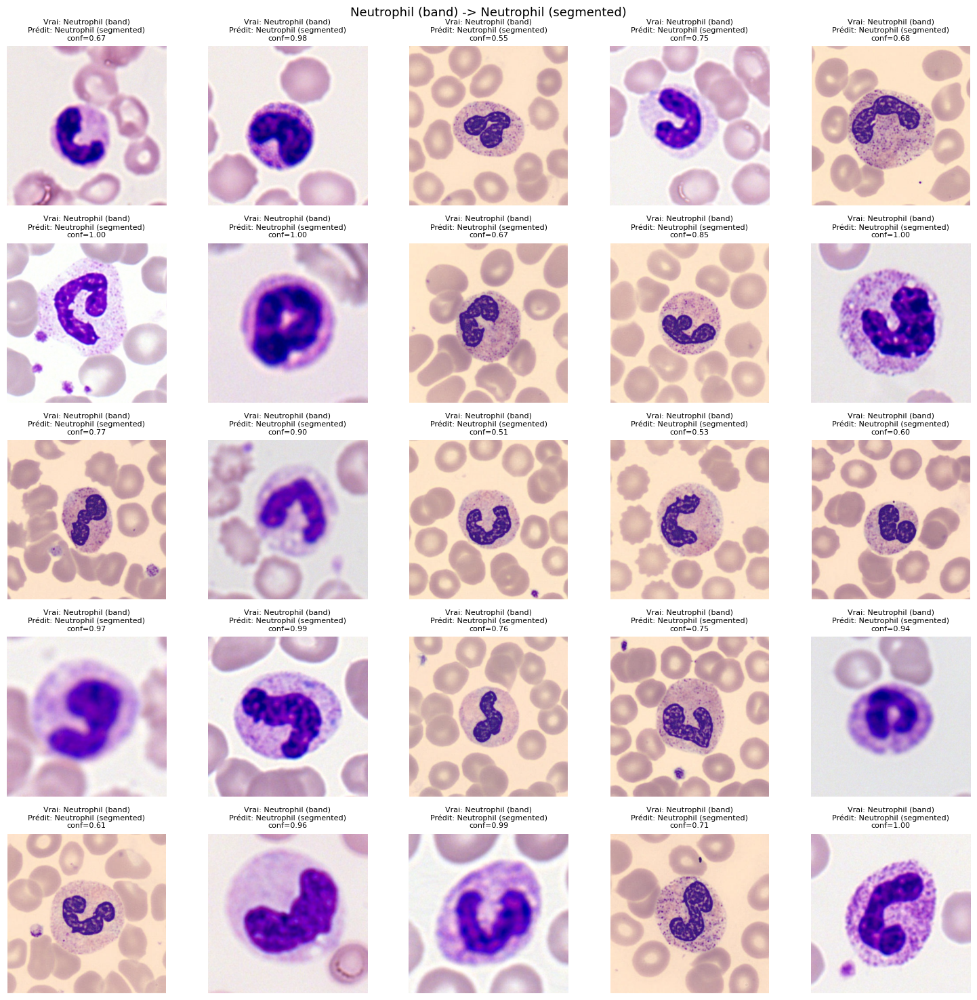

In [12]:
# --- Confusion mutuelle Neutrophil (band) <-> Neutrophil (segmented) ---
show_class_audit("Neutrophil (band)", "Neutrophil (segmented)")


67 images trouvées pour 'Neutrophil (segmented) -> Neutrophil (band)' (sur 1443 images de 'Neutrophil (segmented)' au total dans le test)
Grille sauvegardée : /kaggle/working/audits/audit_Neutrophil_segmented_vers_Neutrophil_band.png


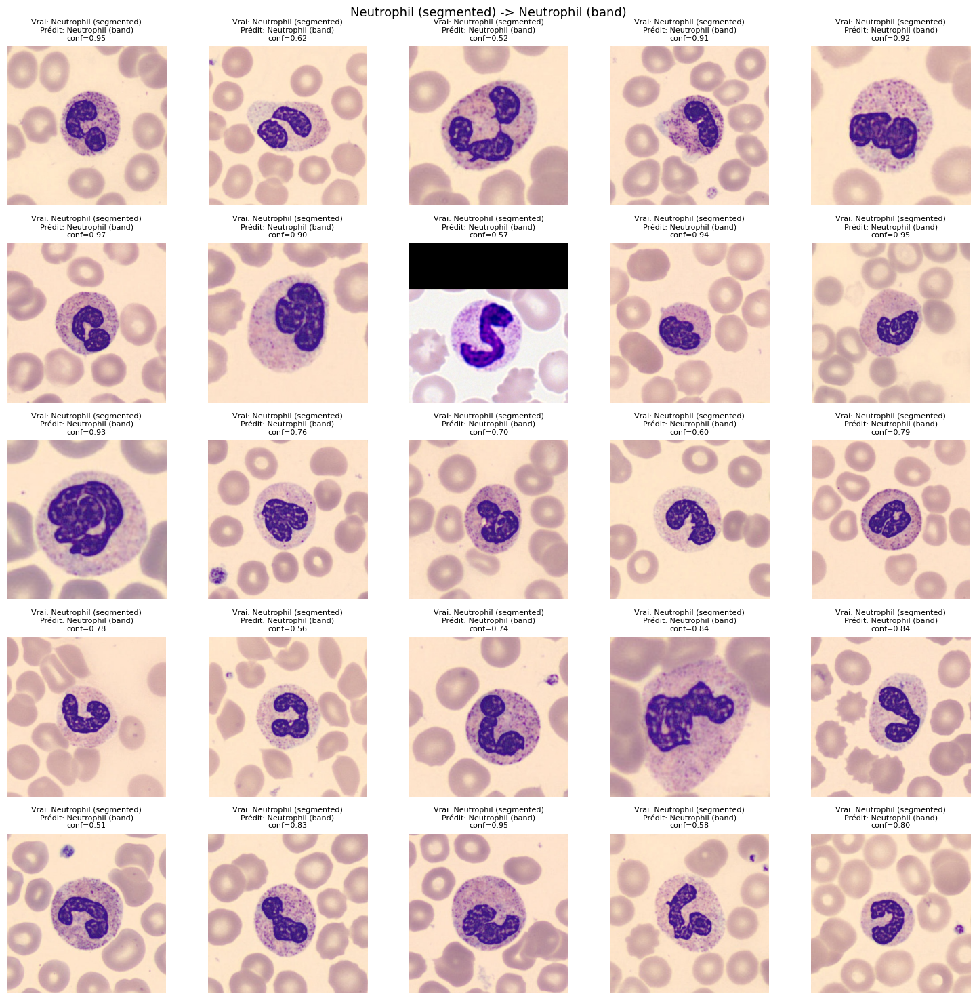

In [13]:
# --- Neutrophil (segmented) -> Neutrophil (band) (sens inverse) ---
show_class_audit("Neutrophil (segmented)", "Neutrophil (band)")


## 8. Exploration libre

Pour auditer une classe/paire non prévue ci-dessus, appelez directement :
```python
show_class_audit("NomDeClasse")                          # toutes les erreurs
show_class_audit("NomDeClasse", "AutreClasse")            # une paire précise
show_class_audit("NomDeClasse", REJECT_LABEL)             # uniquement les rejets
show_class_audit("NomDeClasse", only_errors=False)        # corrects + erreurs, pour comparer
```

In [14]:
# Exemple :
# show_class_audit("Basophil")


---
## 9. Audit de qualité des données (NOUVEAU) -- indépendant des modèles

Ce qui suit **ne nécessite aucun modèle rechargé** -- ça audite les images brutes du dataset
fusionné directement, pas les erreurs de prédiction. Motivé par une image trouvée dans l'audit
`Myelocyte -> Neutrophil (band)` montrant **deux cellules dans le même cadre** -- un signal de
problème de recadrage/annotation, pas de limite du modèle. Deux outils :

- **Navigateur brut** : parcourir un échantillon aléatoire d'une classe, sans filtrer par
  prédiction -- utile pour repérer des problèmes de qualité à l'œil.
- **Détecteur de crops suspects** : heuristique automatique (comptage de contours significatifs
  par seuillage) pour prioriser l'inspection manuelle plutôt que de tout parcourir au hasard.

In [15]:
def show_raw_class_sample(class_name, n=25, seed=42, source_df=None):
    """Affiche un échantillon aléatoire BRUT d'une classe du dataset (pas de prédiction,
    pas de modèle requis) -- pur audit de qualité de données. `source_df` par défaut = tout
    le dataset chargé (train+val+test) ; passez `train_df`/`val_df`/`test_df` pour restreindre."""
    df = source_df if source_df is not None else data
    class_df = df[df["target_label"] == class_name].reset_index(drop=True)
    n_total = len(class_df)
    print(f"{n_total} images pour '{class_name}' dans ce sous-ensemble")
    if n_total == 0:
        return

    sample_size = min(n, n_total)
    sample_idx = np.random.RandomState(seed).choice(n_total, size=sample_size, replace=False)

    n_cols = 5
    n_rows = int(np.ceil(sample_size / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 3, n_rows * 3))
    axes = np.array(axes).reshape(-1)
    for ax, idx in zip(axes, sample_idx):
        img = cv2.cvtColor(cv2.imread(str(class_df.iloc[idx]["path"])), cv2.COLOR_BGR2RGB)
        ax.imshow(img)
        ax.set_title(class_df.iloc[idx]["class_name"], fontsize=8)
        ax.axis("off")
    for ax in axes[sample_size:]:
        ax.axis("off")
    plt.suptitle(f"Échantillon brut -- {class_name}", fontsize=13)
    plt.tight_layout()

    safe_name = re.sub(r"[^A-Za-z0-9]+", "_", class_name).strip("_")
    plt.savefig(AUDIT_DIR / f"qualite_brut_{safe_name}.png", dpi=120, bbox_inches="tight")
    print(f"Grille sauvegardée : {AUDIT_DIR / f'qualite_brut_{safe_name}.png'}")
    plt.show()


In [16]:
def detect_multi_cell_candidates(class_name, n_show=25, seed=42, source_df=None,
                                    min_area_fraction=0.01, ratio_threshold=0.4):
    """Heuristique pour repérer les images contenant potentiellement PLUSIEURS cellules
    (comme le cas Myelocyte à 2 cellules trouvé dans l'audit d'erreurs).

    CORRIGÉ : la première version comptait tous les contours après un simple seuillage en
    niveaux de gris (Otsu) -- problème, les globules rouges environnants (toujours nombreux
    dans une image de frottis) étaient eux aussi comptés comme des "contours significatifs",
    rendant la détection inutilisable (quasi 100% de faux positifs).

    Nouvelle approche, en 2 temps :
    1. Filtrage PAR COULEUR (teinte violette/bleue du noyau coloré, dans l'espace HSV) --
       isole le noyau du fond rose pâle des globules rouges. Un nettoyage morphologique
       (fermeture puis ouverture) fusionne les fragments de texture interne du noyau.
    2. Ne compte que les contours dont l'aire est comparable à celle du plus grand
       (>= `ratio_threshold` de l'aire du noyau principal) -- élimine les petits artefacts
       de bord des globules rouges (qui captent parfois un peu de teinte violette sur leur
       pourtour), sans pour autant ignorer un vrai second noyau de taille similaire.

    Ce n'est toujours PAS une détection parfaite -- juste un pré-filtre, à vérifier
    visuellement avant toute conclusion."""
    df = source_df if source_df is not None else data
    class_df = df[df["target_label"] == class_name].reset_index(drop=True)
    n_total = len(class_df)
    if n_total == 0:
        print(f"Aucune image pour '{class_name}'")
        return

    kernel = np.ones((9, 9), np.uint8)
    scores = []
    for i in range(n_total):
        img = cv2.imread(str(class_df.iloc[i]["path"]), cv2.IMREAD_COLOR)
        if img is None:
            continue
        hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
        # Teinte violette/bleue caractéristique de la coloration du noyau (Wright-Giemsa
        # et équivalents) -- exclut le rose pâle des globules rouges et le fond clair.
        mask = cv2.inRange(hsv, (110, 40, 20), (170, 255, 255))
        mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)
        mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)
        contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        img_area = img.shape[0] * img.shape[1]
        areas = sorted([cv2.contourArea(c) for c in contours if cv2.contourArea(c) > img_area * min_area_fraction],
                        reverse=True)
        if not areas:
            scores.append((i, 0, 0))
            continue
        primary = areas[0]
        n_second = sum(1 for a in areas[1:] if a >= primary * ratio_threshold)
        scores.append((i, n_second, len(areas)))

    n_multi = sum(1 for _, n_second, _ in scores if n_second >= 1)
    print(f"{class_name} : {n_multi}/{len(scores)} images avec au moins un second noyau "
          f"de taille comparable détecté (candidats à un problème de recadrage -- à vérifier "
          f"visuellement, cette heuristique produit encore des faux positifs/négatifs)")

    scores.sort(key=lambda x: -x[1])
    top = scores[:n_show]
    if top[0][1] < 1:
        print("Aucun candidat suspect trouvé -- rien à afficher.")
        return

    n_cols = 5
    n_rows = int(np.ceil(len(top) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 3, n_rows * 3))
    axes = np.array(axes).reshape(-1)
    for ax, (idx, n_second, n_total_contours) in zip(axes, top):
        img = cv2.cvtColor(cv2.imread(str(class_df.iloc[idx]["path"])), cv2.COLOR_BGR2RGB)
        ax.imshow(img)
        ax.set_title(f"{n_second} second(s) noyau(x) probable(s)", fontsize=8)
        ax.axis("off")
    for ax in axes[len(top):]:
        ax.axis("off")
    plt.suptitle(f"Candidats crops suspects (triés) -- {class_name}", fontsize=13)
    plt.tight_layout()

    safe_name = re.sub(r"[^A-Za-z0-9]+", "_", class_name).strip("_")
    plt.savefig(AUDIT_DIR / f"qualite_suspects_{safe_name}.png", dpi=120, bbox_inches="tight")
    print(f"Grille sauvegardée : {AUDIT_DIR / f'qualite_suspects_{safe_name}.png'}")
    plt.show()


## 10. Audits de qualité pré-configurés -- les 3 classes identifiées

`Myelocyte` (signal concret trouvé), `Promyelocyte` et `Monoblast` (manque de données déjà
diagnostiqué -- vérifier qu'il ne s'y ajoute pas aussi des soucis de qualité).

Myelocyte : 12/1140 images avec au moins un second noyau de taille comparable détecté (candidats à un problème de recadrage -- à vérifier visuellement, cette heuristique produit encore des faux positifs/négatifs)
Grille sauvegardée : /kaggle/working/audits/qualite_suspects_Myelocyte.png


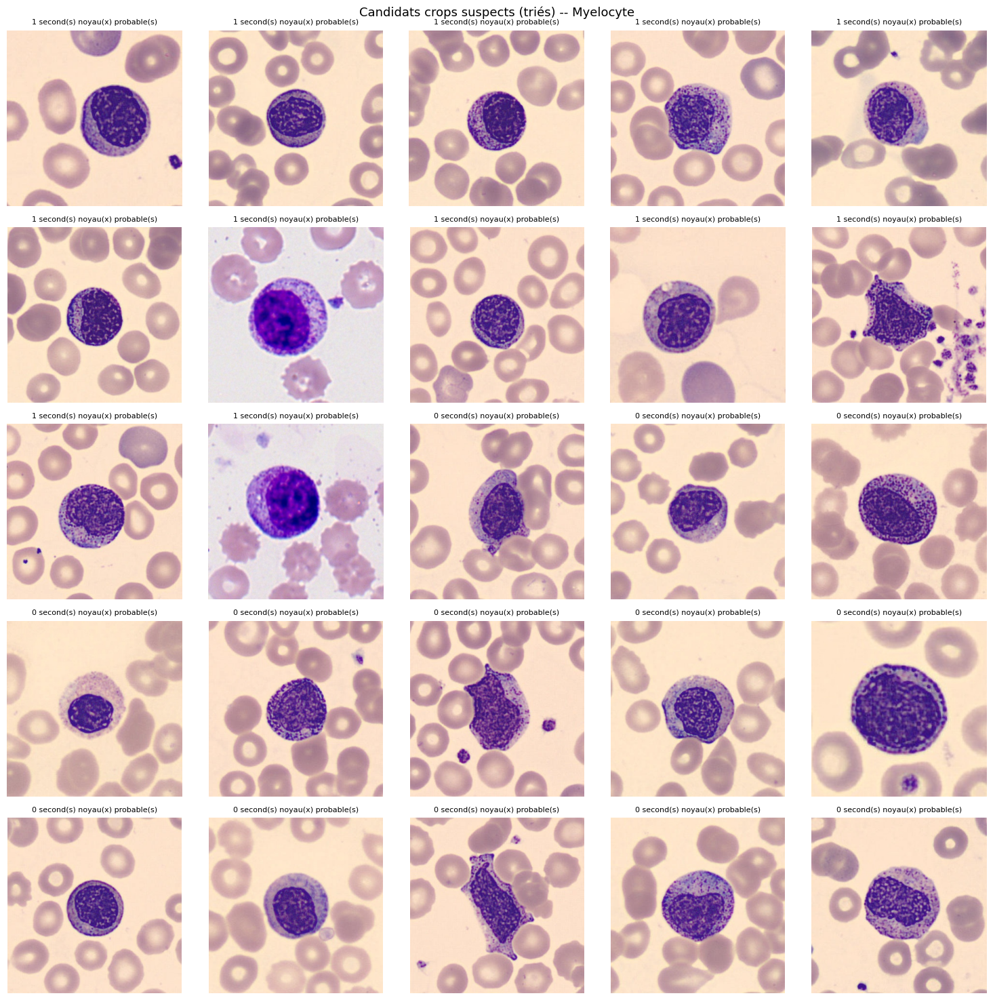

In [17]:
detect_multi_cell_candidates("Myelocyte")


Promyelocyte : 1/647 images avec au moins un second noyau de taille comparable détecté (candidats à un problème de recadrage -- à vérifier visuellement, cette heuristique produit encore des faux positifs/négatifs)
Grille sauvegardée : /kaggle/working/audits/qualite_suspects_Promyelocyte.png


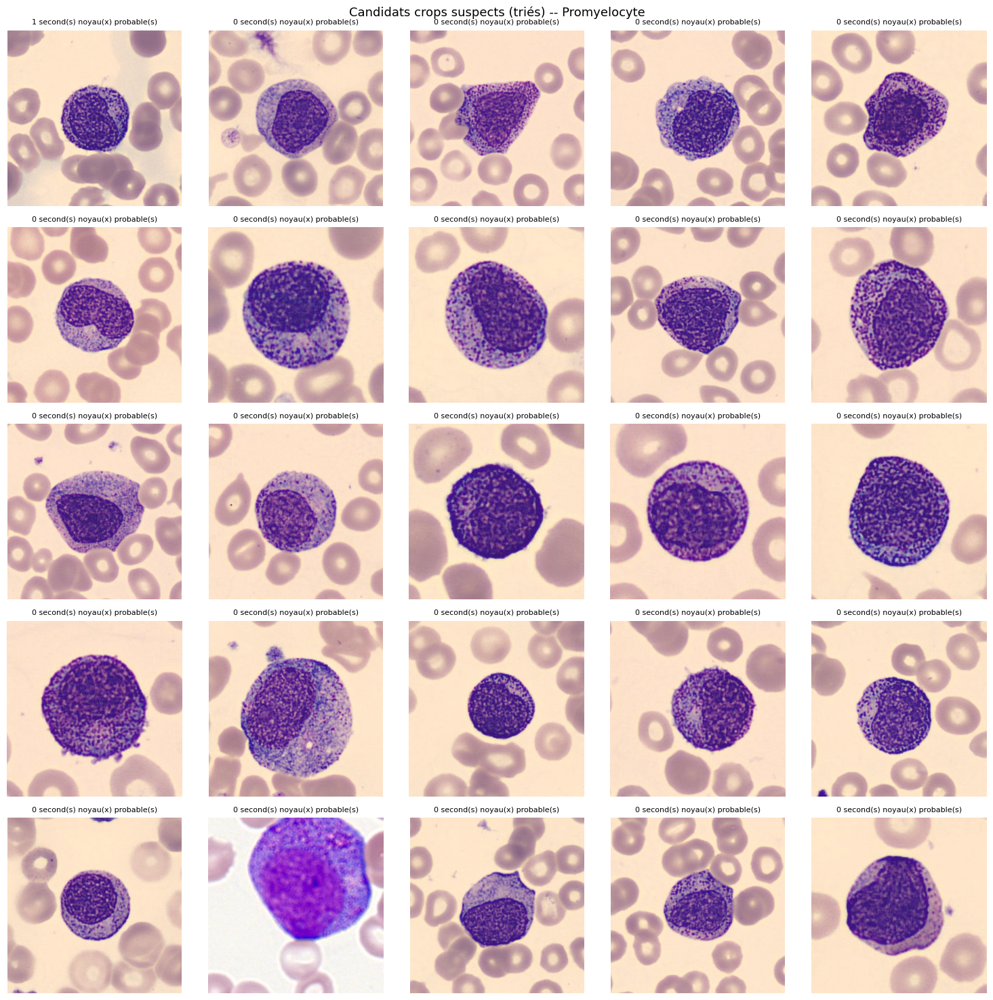

In [18]:
detect_multi_cell_candidates("Promyelocyte")


In [19]:
detect_multi_cell_candidates("Monoblast")


Monoblast : 0/21 images avec au moins un second noyau de taille comparable détecté (candidats à un problème de recadrage -- à vérifier visuellement, cette heuristique produit encore des faux positifs/négatifs)
Aucun candidat suspect trouvé -- rien à afficher.


1140 images pour 'Myelocyte' dans ce sous-ensemble
Grille sauvegardée : /kaggle/working/audits/qualite_brut_Myelocyte.png


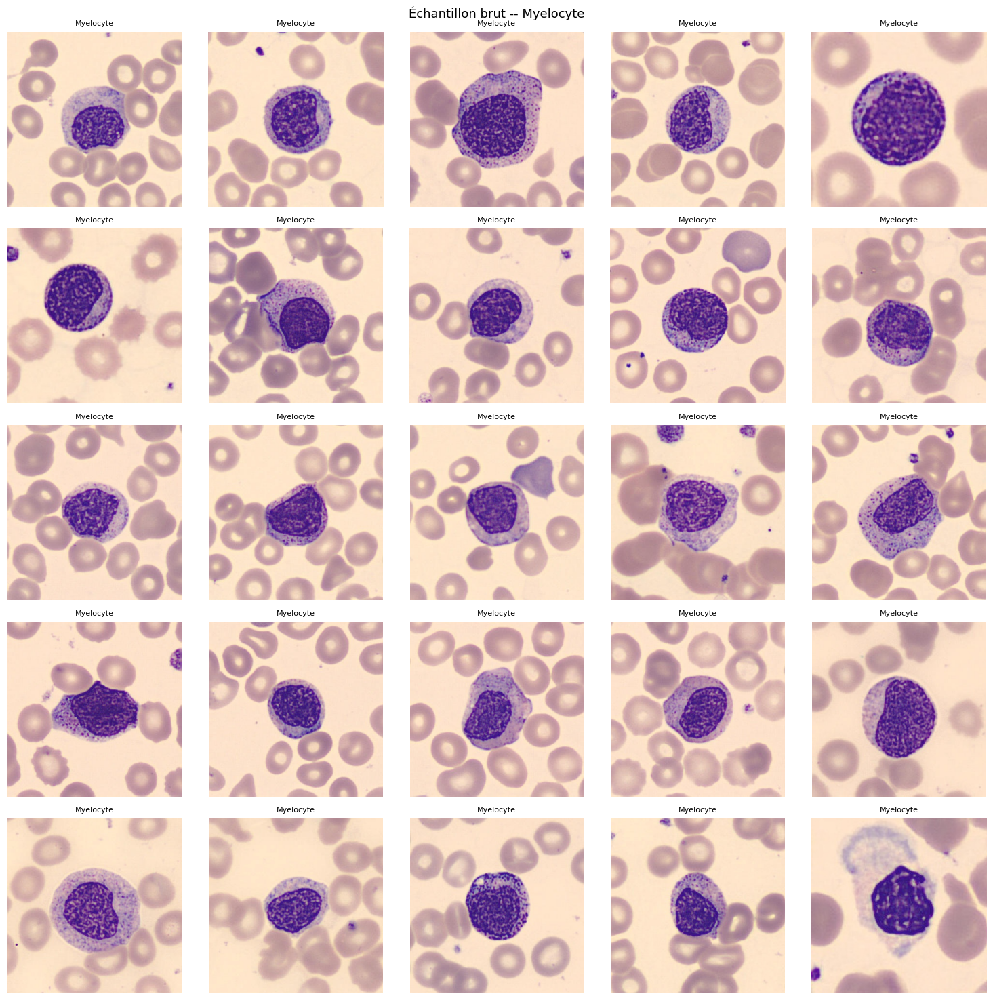

In [20]:
show_raw_class_sample("Myelocyte")
